In [ ]:

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf

In [ ]:
# Download Stock Data
def load_stock_data(ticker, start_date, end_date):
    data = yf.download(ticker, start=start_date, end=end_date)
    return data

ticker = "AAPL"
start_date = "2015-01-01"
end_date = "2025-01-01"

df = load_stock_data(ticker, start_date, end_date)

df.head()

/tmp/ipykernel_663/2746809192.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.192596,24.659498,23.754460,24.648434,212818400
2015-01-05,23.511051,24.042125,23.325176,23.962464,257142000
2015-01-06,23.513273,23.772171,23.152585,23.575232,263188400
2015-01-07,23.842987,23.942563,23.610642,23.721282,160423600
2015-01-08,24.759085,24.816618,24.053199,24.170479,237458000


In [ ]:

df.head()

df.tail()

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (2516, 5)

Columns:
MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Data Types:
Price   Ticker
Close   AAPL      float64
High    AAPL      float64
Low     AAPL      float64
Open    AAPL      float64
Volume  AAPL        int64
dtype: object

Missing Values:
Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

Summary Statistics:
Price         Close         High          Low         Open        Volume
Ticker         AAPL         AAPL         AAPL         AAPL          AAPL
count   2516.000000  2516.000000  2516.000000  2516.000000  2.516000e+03
mean      93.684877    94.594694    92.673089    93.598213  1.170853e+08
std       65.319931    65.912255    64.634534    65.239867  6.839614e+07
min       20.565870    20.868641    20.367816    20.488467  2.3

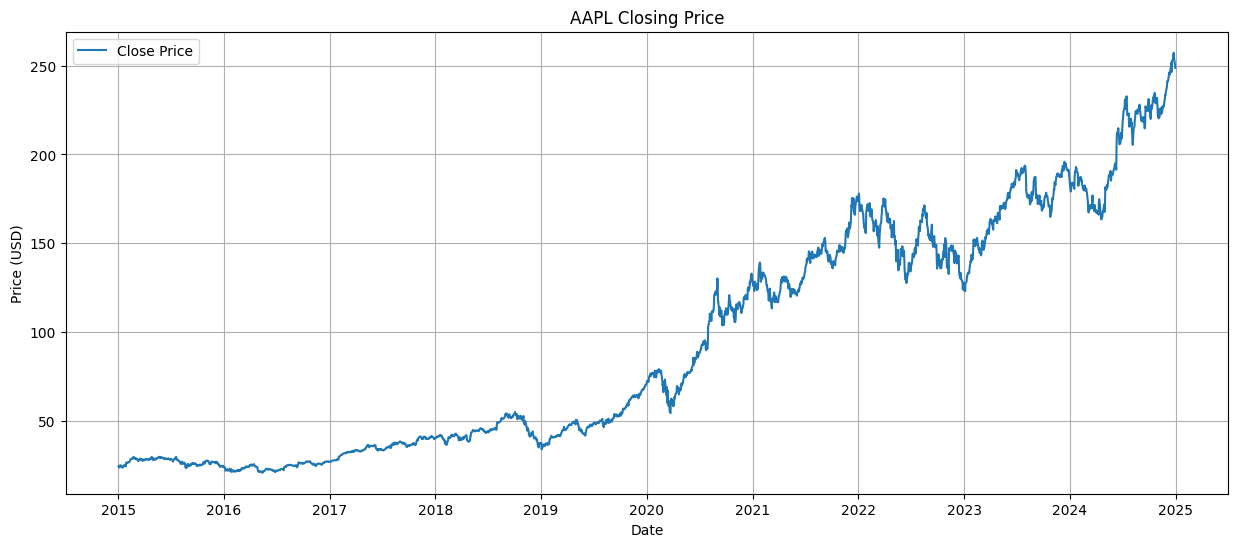

In [ ]:

plt.figure(figsize=(15, 6))

plt.plot(df.index, df["Close"], label="Close Price")

plt.title(f"{ticker} Closing Price")

plt.xlabel("Date")

plt.ylabel("Price (USD)")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:

features = ["Open", "High", "Low", "Close", "Volume"]
data = df[features]

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

print("Scaled Data Shape:", scaled_data.shape)

print(scaled_data[:5])

Scaled Data Shape: (2516, 5)
[[0.01762232 0.01595612 0.01437293 0.01531494 0.3030476 ]
 [0.01471643 0.01335753 0.01255105 0.01243691 0.37389842]
 [0.01307605 0.01222127 0.01181857 0.01244629 0.38356353]
 [0.01369475 0.01293846 0.01376256 0.01383861 0.21929505]
 [0.01559762 0.01661746 0.01564078 0.01770711 0.34243375]]


In [ ]:
sequence_length = 60

X = []
y = []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, 3])

X = np.array(X)
y = np.array(y)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (2456, 60, 5)
Target Shape: (2456,)


In [ ]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training Input Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("Testing Input Shape:", X_test.shape)
print("Testing Target Shape:", y_test.shape)

Training Input Shape: (1964, 60, 5)
Training Target Shape: (1964,)
Testing Input Shape: (492, 60, 5)
Testing Target Shape: (492,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()

model.add(LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2))

model.add(LSTM(32))
model.add(Dropout(0.2))

model.add(Dense(16, activation="relu"))
model.add(Dense(1))

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - loss: 0.0046 - mae: 0.0386 - val_loss: 0.0038 - val_mae: 0.0476
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 0.0013 - mae: 0.0223 - val_loss: 0.0072 - val_mae: 0.0730
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - loss: 0.0011 - mae: 0.0197 - val_loss: 0.0143 - val_mae: 0.1105
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - loss: 0.0011 - mae: 0.0207 - val_loss: 0.0085 - val_mae: 0.0803
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 9.1701e-04 - mae: 0.0186 - val_loss: 0.0096 - val_mae: 0.0874
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 9.3504e-04 - mae: 0.0189 - val_loss: 0.0124 - val_mae: 0.1024
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 8.1920e-04 - mae: 0.0179 - val_loss: 0.0062 - val_mae: 0.0660
Epoch 8/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 7.6719e-04 - mae: 0.0169 - val_loss: 0.0085 - val_mae: 0.0819
Epoch 9/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 

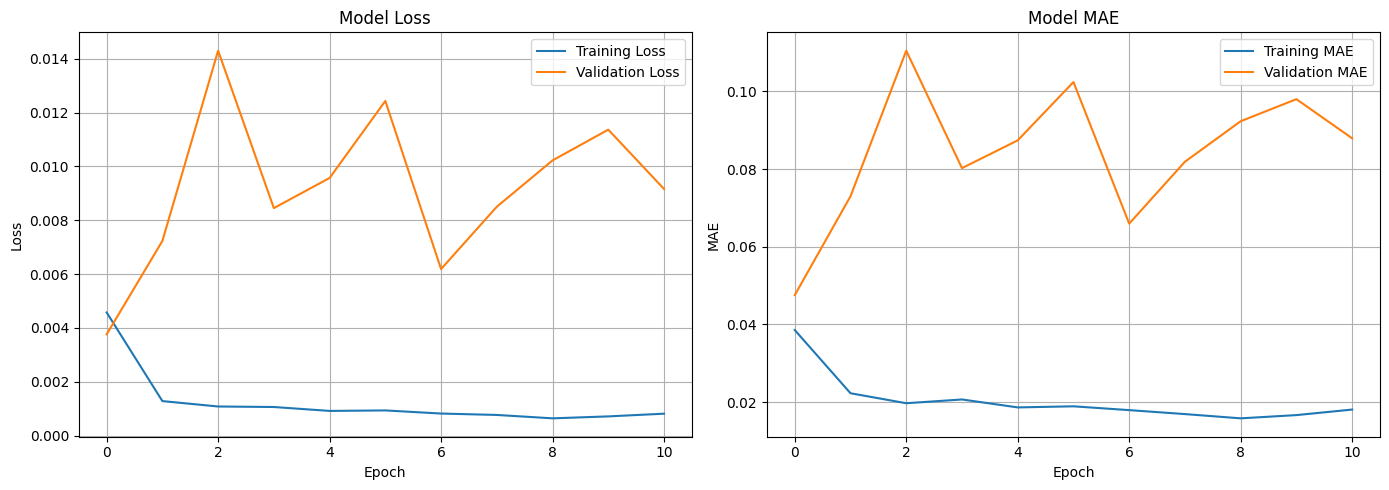

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("Model MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
y_pred = model.predict(X_test)

print("Prediction Shape:", y_pred.shape)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Prediction Shape: (492, 1)


In [ ]:
dummy_pred = np.zeros((len(y_pred), 5))
dummy_actual = np.zeros((len(y_test), 5))

dummy_pred[:, 3] = y_pred.flatten()
dummy_actual[:, 3] = y_test

y_pred_actual = scaler.inverse_transform(dummy_pred)[:, 3]
y_test_actual = scaler.inverse_transform(dummy_actual)[:, 3]

In [ ]:
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mae = mean_absolute_error(y_test_actual, y_pred_actual)
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")

RMSE : 14.52
MAE  : 11.26
R²   : 0.7103


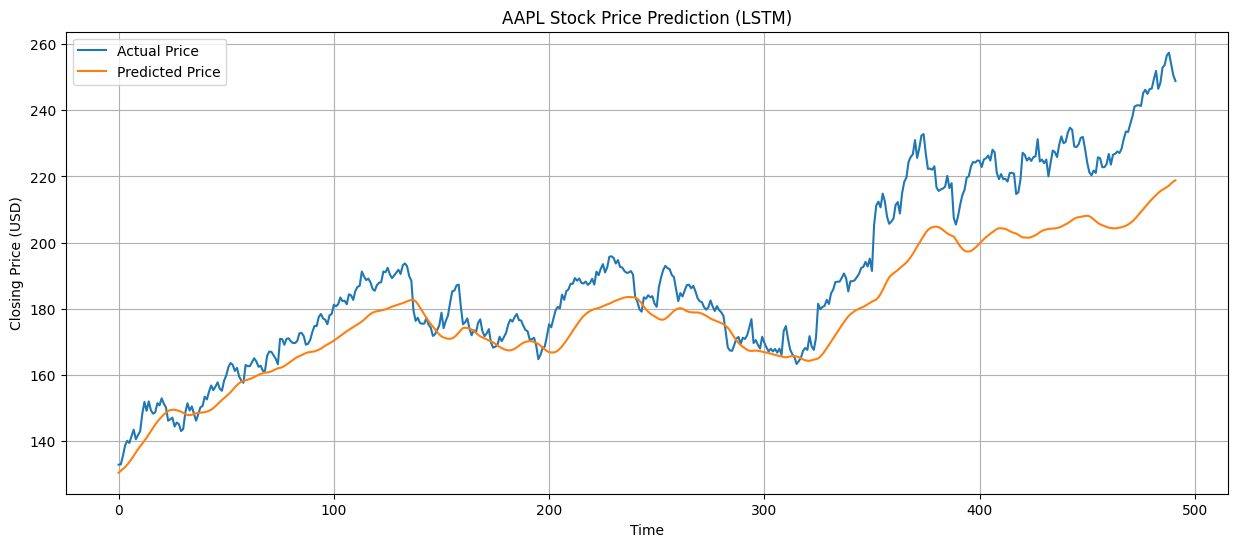

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(y_test_actual, label="Actual Price")
plt.plot(y_pred_actual, label="Predicted Price")

plt.title(f"{ticker} Stock Price Prediction (LSTM)")
plt.xlabel("Time")
plt.ylabel("Closing Price (USD)")

plt.legend()
plt.grid(True)

plt.show()

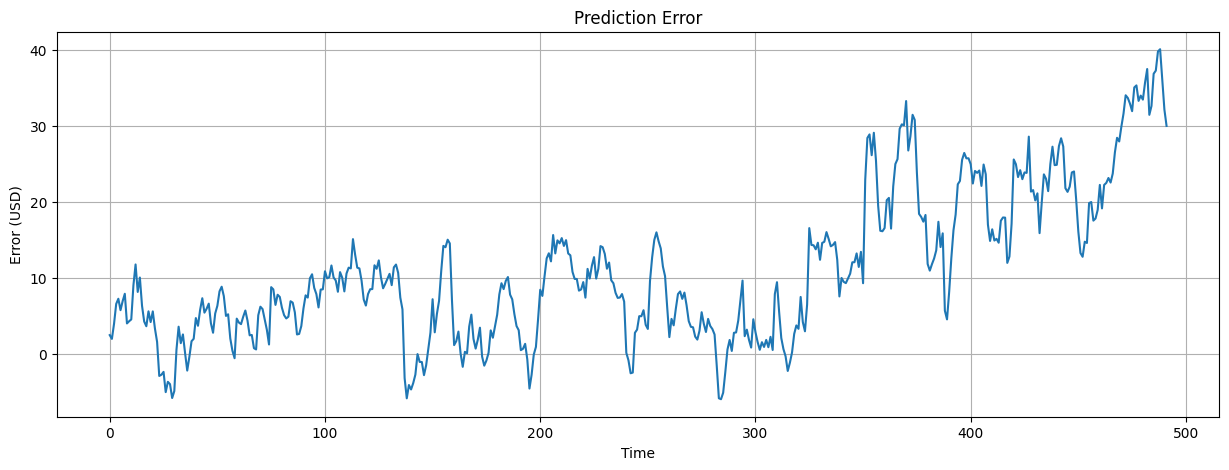

In [ ]:
errors = y_test_actual - y_pred_actual

plt.figure(figsize=(15, 5))

plt.plot(errors)

plt.title("Prediction Error")
plt.xlabel("Time")
plt.ylabel("Error (USD)")

plt.grid(True)

plt.show()

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)

In [ ]:
class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, sequence_length, d_model):
        super().__init__()

        position = np.arange(sequence_length)[:, np.newaxis]
        dimension = np.arange(d_model)[np.newaxis, :]

        angle_rates = 1 / np.power(10000, (2 * (dimension // 2)) / np.float32(d_model))
        angle_rads = position * angle_rates

        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])

        self.positional_encoding = tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)

    def call(self, inputs):
        return inputs + self.positional_encoding

In [ ]:
class TransformerEncoder(tf.keras.layers.Layer):

    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1):
        super().__init__()

        self.attention = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )

        self.ffn = tf.keras.Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(d_model)
        ])

        self.norm1 = LayerNormalization(epsilon=1e-6)
        self.norm2 = LayerNormalization(epsilon=1e-6)

        self.dropout1 = Dropout(dropout_rate)
        self.dropout2 = Dropout(dropout_rate)

    def call(self, inputs, training=False):

        attention_output = self.attention(
            inputs,
            inputs
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        out1 = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(out1)

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        output = self.norm2(
            out1 + ffn_output
        )

        return output

In [ ]:
d_model = 64
num_heads = 4
ff_dim = 128
dropout_rate = 0.1
num_encoder_blocks = 2

inputs = Input(shape=(X_train.shape[1], X_train.shape[2]))

x = Dense(d_model)(inputs)

x = PositionalEncoding(
    sequence_length=X_train.shape[1],
    d_model=d_model
)(x)

for _ in range(num_encoder_blocks):
    x = TransformerEncoder(
        d_model=d_model,
        num_heads=num_heads,
        ff_dim=ff_dim,
        dropout_rate=dropout_rate
    )(x)

from tensorflow.keras.layers import Lambda

x = Lambda(lambda t: t[:, -1, :])(x)

dense_units = 32
x = Dense(dense_units, activation="relu")(x)

outputs = Dense(1)(x)

transformer_model = Model(inputs=inputs, outputs=outputs)

transformer_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

transformer_model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 60, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 60, 64)         │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding_2           │ (None, 60, 64)         │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_4           │ (None, 60, 64)         │        33,472 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_5           │ (None, 60, 64)         │        33,472 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,441 (271.25 KB)

 Trainable params: 69,441 (271.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

transformer_history = transformer_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 129ms/step - loss: 0.0477 - mae: 0.1473 - val_loss: 0.0037 - val_mae: 0.0493
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - loss: 0.0079 - mae: 0.0700 - val_loss: 0.0018 - val_mae: 0.0338
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - loss: 0.0042 - mae: 0.0512 - val_loss: 0.0017 - val_mae: 0.0350
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - loss: 0.0032 - mae: 0.0443 - val_loss: 0.0016 - val_mae: 0.0313
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - loss: 0.0025 - mae: 0.0389 - val_loss: 0.0026 - val_mae: 0.0407
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - loss: 0.0019 - mae: 0.0350 - val_loss: 0.0030 - val_mae: 0.0444
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - loss: 0.0018 - mae: 0.0330 - val_loss: 0.0033 - val_mae: 0.0461
Epoch 8/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 123ms/step - loss: 0.0015 - mae: 0.0304 - val_loss: 0.0040 - val_mae: 0.0539
Epoch 9/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/s

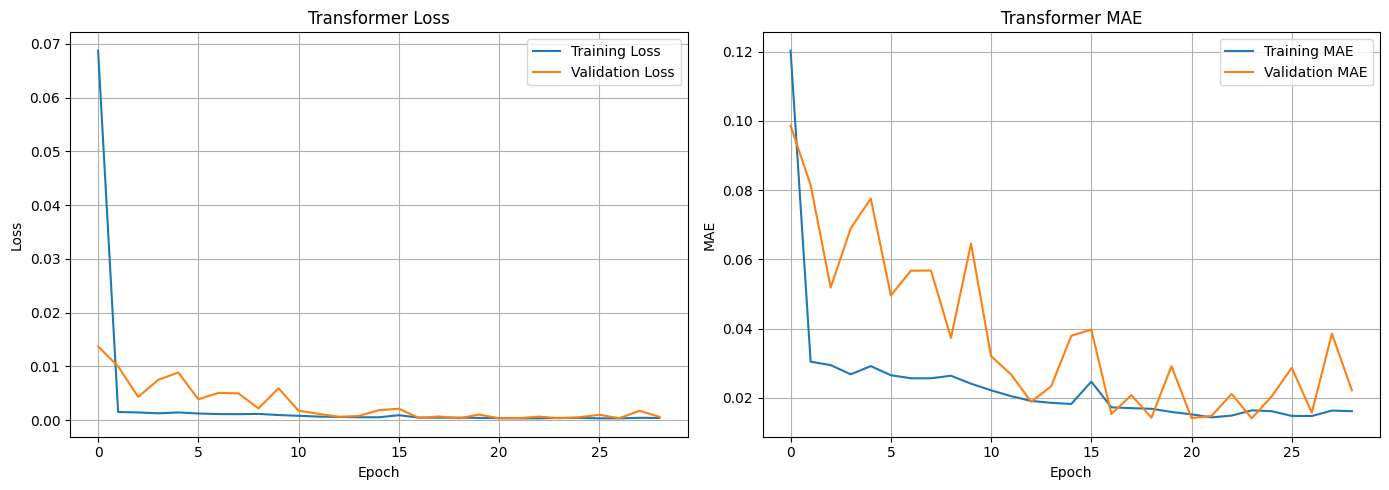

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(transformer_history.history["loss"], label="Training Loss")
plt.plot(transformer_history.history["val_loss"], label="Validation Loss")
plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(transformer_history.history["mae"], label="Training MAE")
plt.plot(transformer_history.history["val_mae"], label="Validation MAE")
plt.title("Transformer MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
transformer_pred = transformer_model.predict(X_test)

print("Prediction Shape:", transformer_pred.shape)

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step
Prediction Shape: (492, 1)


In [ ]:
dummy_pred = np.zeros((len(transformer_pred), 5))
dummy_actual = np.zeros((len(y_test), 5))

dummy_pred[:, 3] = transformer_pred.flatten()
dummy_actual[:, 3] = y_test

transformer_pred_actual = scaler.inverse_transform(dummy_pred)[:, 3]
transformer_actual = scaler.inverse_transform(dummy_actual)[:, 3]

In [ ]:
transformer_rmse = np.sqrt(mean_squared_error(transformer_actual, transformer_pred_actual))
transformer_mae = mean_absolute_error(transformer_actual, transformer_pred_actual)
transformer_r2 = r2_score(transformer_actual, transformer_pred_actual)

print(f"RMSE : {transformer_rmse:.2f}")
print(f"MAE  : {transformer_mae:.2f}")
print(f"R²   : {transformer_r2:.4f}")

RMSE : 323.40
MAE  : 322.06
R²   : -142.6828


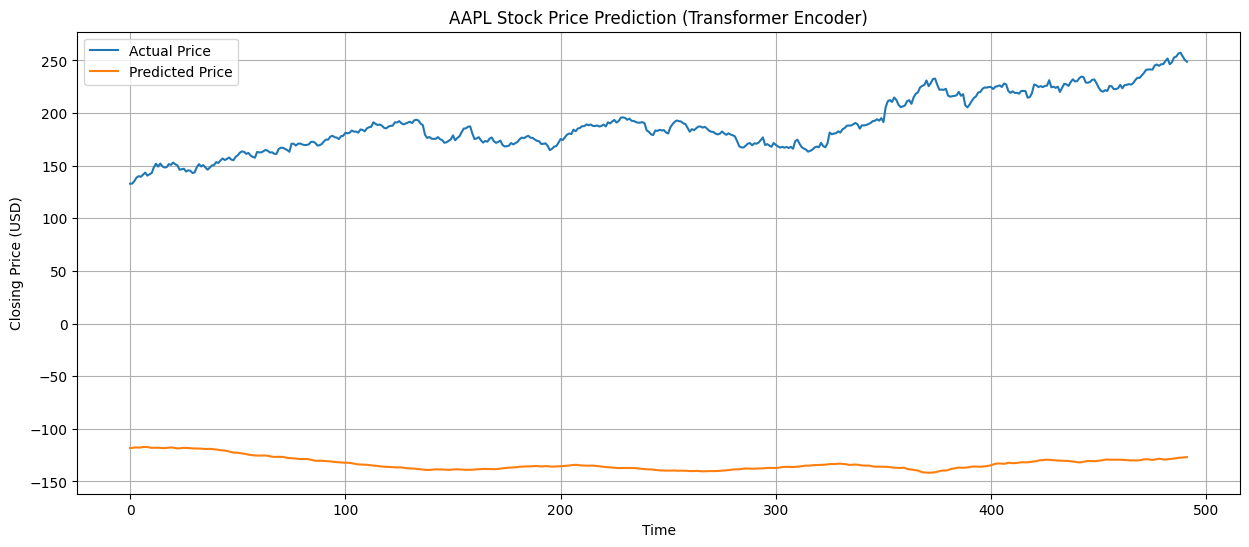

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(transformer_actual, label="Actual Price")
plt.plot(transformer_pred_actual, label="Predicted Price")

plt.title(f"{ticker} Stock Price Prediction (Transformer Encoder)")
plt.xlabel("Time")
plt.ylabel("Closing Price (USD)")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(transformer_pred[:10])
print(y_test[:10])

[[-0.58581734]
 [-0.58561975]
 [-0.5838754 ]
 [-0.58373713]
 [-0.58405423]
 [-0.58342236]
 [-0.582039  ]
 [-0.58181983]
 [-0.58208793]
 [-0.5835699 ]]
[0.47459036 0.47483953 0.48563565 0.49908919 0.50498542 0.50220338
 0.51092341 0.51910328 0.50693696 0.51229355]


In [ ]:
print("Prediction Min:", transformer_pred.min())
print("Prediction Max:", transformer_pred.max())

print("Target Min:", y_test.min())
print("Target Max:", y_test.max())

Prediction Min: -0.6851006
Prediction Max: -0.58181983
Target Min: 0.4745903615235125
Target Max: 1.0
